In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler
import torch
from torch.utils.data import TensorDataset
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as PyGDataLoader 

In [3]:

# --- 1. Load and Engineer Features ---
df = pd.read_csv("Dimuon_Singlemu.csv")
df = df.drop(columns=['Run', 'Event']).drop_duplicates()


<h1> Physics Feature Engineering

In [4]:

df['eta_diff'] = df['eta1'] - df['eta2']

# Pseudorapidity Difference


df['phi_diff'] = np.arctan2(np.sin(df['phi1'] - df['phi2']), np.cos(df['phi1'] - df['phi2']))

# Azimuthal Angle Difference


df['delta_R'] = np.sqrt(df['eta_diff']**2 + df['phi_diff']**2)

# Angular Seperation between 2 muons


df['pt_ratio'] = df['pt1'] / (df['pt2'] + 1e-5)

# Tranverse Momentum Ratio


df['pt_sum'] = df['pt1'] + df['pt2']

# Sum of Transverse Momentum

<h1> Global Event Kinematics

In [5]:
df['E_total'] = df['E1'] + df['E2']
# Total Relativistic Energy

df['px_total'] = df['px1'] + df['px2']
# Total Horizontal Momentum

df['py_total'] = df['py1'] + df['py2']
# Total Vertical Momentum

df['pz_total'] = df['pz1'] + df['pz2']
# Total Longitudinal Momentum

<h1> Encode Muon Types - Global and Tracker Muon

In [6]:
df['type1'] = df['type1'].map({'G': 1, 'T': 0}).fillna(-1)
df['type2'] = df['type2'].map({'G': 1, 'T': 0}).fillna(-1)

<h1> VISUALIZATION 1: Resonance Segregation via Delta R


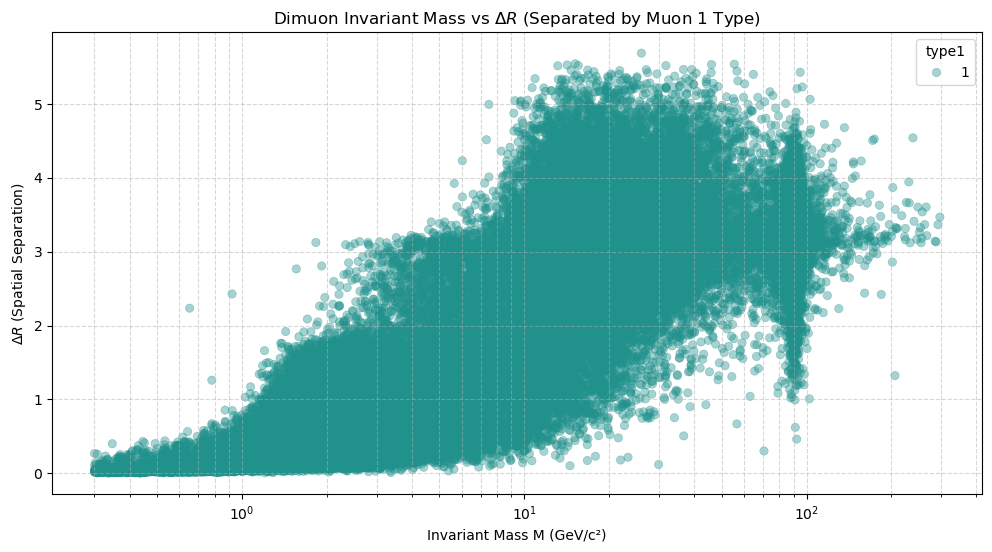

In [7]:
# Helps us see if different physics particles show distinct spatial properties
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df, x='M', y='delta_R', 
    hue='type1', palette='viridis', alpha=0.4, edgecolor=None
)
plt.xscale('log')
plt.title("Dimuon Invariant Mass vs $\Delta R$ (Separated by Muon 1 Type)")
plt.xlabel("Invariant Mass M (GeV/c²)")
plt.ylabel("$\Delta R$ (Spatial Separation)")
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.show()


<h1> 2. Train / Val / Test Splitting


In [8]:
X = df.drop(columns=['M'])  # Retain engineered features for global graph context
y = df['M']

In [9]:
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1765, random_state=42)


<h1> Scaling


In [10]:
# Isolate Continuous vs Categorical/Discrete variables


kinematic_cols = ['pt1', 'eta1', 'phi1', 'E1', 'px1', 'py1', 'pz1', 
                  'pt2', 'eta2', 'phi2', 'E2', 'px2', 'py2', 'pz2']



global_cols = ['eta_diff', 'phi_diff', 'delta_R', 'pt_ratio', 'pt_sum', 'E_total', 'px_total', 'py_total', 'pz_total']




discrete_cols = ['type1', 'Q1', 'type2', 'Q2']


In [11]:
# Scale kinematics and global features dynamically

scaler_X = RobustScaler()
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

In [12]:
X_train_scaled[kinematic_cols + global_cols] = scaler_X.fit_transform(X_train[kinematic_cols + global_cols])
X_val_scaled[kinematic_cols + global_cols] = scaler_X.transform(X_val[kinematic_cols + global_cols])
X_test_scaled[kinematic_cols + global_cols] = scaler_X.transform(X_test[kinematic_cols + global_cols])

In [13]:
# Scale Target Logarithmically or Standard scaled (Log helps handles wide 0.3 - 300 GeV range)

scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(np.log10(y_train).values.reshape(-1, 1)).flatten()
y_val_scaled = scaler_y.transform(np.log10(y_val).values.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(np.log10(y_test).values.reshape(-1, 1)).flatten()

<h1> VISUALIZATION 2: Pre vs Post Scaling Distributions

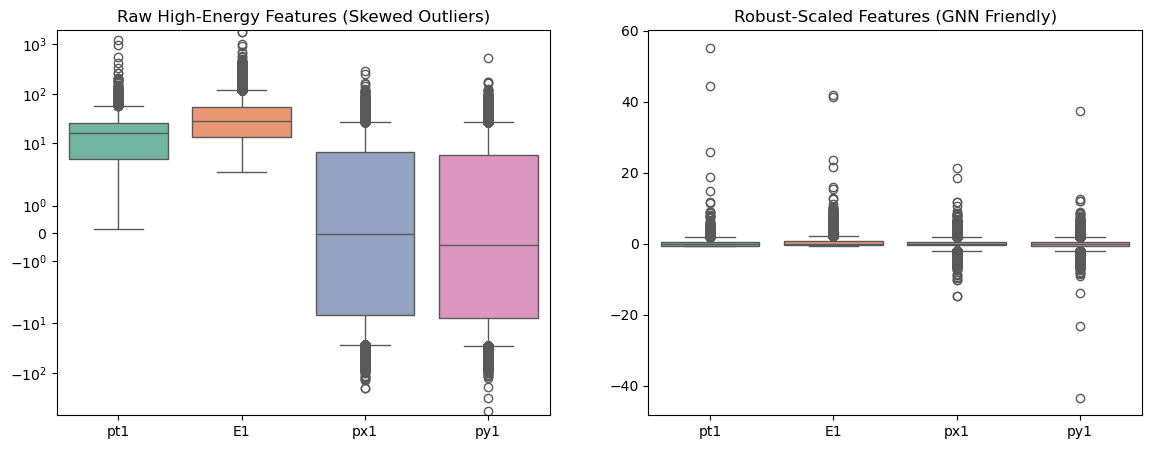

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=X_train[['pt1', 'E1', 'px1', 'py1']], ax=ax1, palette='Set2')
ax1.set_title("Raw High-Energy Features (Skewed Outliers)")
ax1.set_yscale('symlog')

sns.boxplot(data=X_train_scaled[['pt1', 'E1', 'px1', 'py1']], ax=ax2, palette='Set2')
ax2.set_title("Robust-Scaled Features (GNN Friendly)")
plt.show()

<h1> Conversion to Tensors & Node Grouping

In [15]:
X_train_tensor = torch.tensor(X_train_scaled.values, dtype=torch.float32)
# Training Features

X_val_tensor = torch.tensor(X_val_scaled.values, dtype=torch.float32)
# Validation Features

X_test_tensor = torch.tensor(X_test_scaled.values, dtype=torch.float32)
# Testing Features


y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32).unsqueeze(1)
# Training Target variables

y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32).unsqueeze(1)
# Validation Target variables

y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32).unsqueeze(1)
# Testing Target Variables

In [16]:
# Extract indices for mapping to nodes

muon1_features = ['type1', 'Q1', 'pt1', 'eta1', 'phi1', 'E1', 'px1', 'py1', 'pz1']
# Muon features of Particle type 1

muon2_features = ['type2', 'Q2', 'pt2', 'eta2', 'phi2', 'E2', 'px2', 'py2', 'pz2']
# Muon Features of particle type 2

idx_muon1 = [X.columns.get_loc(c) for c in muon1_features]
# Indice of Muon 1

idx_muon2 = [X.columns.get_loc(c) for c in muon2_features]
# Indice of Muon 2

idx_global = [X.columns.get_loc(c) for c in global_cols]
# Indice of both


In [17]:
# Node Matrix Generation

def structure_gnn_nodes(tensor):
    n1 = tensor[:, idx_muon1].unsqueeze(1)
    n2 = tensor[:, idx_muon2].unsqueeze(1)
    return torch.cat([n1, n2], dim=1)

In [18]:
X_train_gnn_nodes = structure_gnn_nodes(X_train_tensor)
# Training nodes for GNN

X_val_gnn_nodes = structure_gnn_nodes(X_val_tensor)
# Validation nodes for GNN

X_test_gnn_nodes = structure_gnn_nodes(X_test_tensor)
# Testing Nodes for GNN

In [19]:
edge_index = torch.tensor([[0, 1], [1, 0]], dtype=torch.long)

<h1> PyG Data List Construction with Global Context

In [20]:
def make_pyg_list(nodes, targets, global_tensor, edge_index):
    data_list = []
    for i in range(nodes.shape[0]):
        # Store global features inside u to feed directly to a global pooling layer
        data_list.append(Data(
            x=nodes[i], 
            edge_index=edge_index, 
            y=targets[i], 
            u=global_tensor[i].unsqueeze(0)
        ))
    return data_list

In [21]:
train_dataset = make_pyg_list(X_train_gnn_nodes, y_train_tensor, X_train_tensor[:, idx_global], edge_index)
val_dataset = make_pyg_list(X_val_gnn_nodes, y_val_tensor, X_val_tensor[:, idx_global], edge_index)
test_dataset = make_pyg_list(X_test_gnn_nodes, y_test_tensor, X_test_tensor[:, idx_global], edge_index)

<h1> Loaders

In [22]:
train_loader = PyGDataLoader(train_dataset, batch_size=256, shuffle=True)
# Loader for Training Dataset

val_loader = PyGDataLoader(val_dataset, batch_size=512, shuffle=False)
# loader for Validation Dataset

test_loader = PyGDataLoader(test_dataset, batch_size=512, shuffle=False)
#  Loader for Testing Dataset


print(f"Sample Batch: {next(iter(train_loader))}")

Sample Batch: DataBatch(x=[512, 9], edge_index=[2, 512], y=[256], u=[256, 9], batch=[512], ptr=[257])


<h1> GRAPH NEURAL NETWORKS

<h3> Using GINE (Graph Isomorphism Network with Edge Features)

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GINEConv, global_mean_pool, global_max_pool

<h2> Model Architecture - Graph Isomorphism Network with Edge Features

In [24]:
class DimuonGNNRegressor(nn.Module):
    def __init__(self, node_in_feats=9, global_in_feats=9, hidden_dim=64):
        super(DimuonGNNRegressor, self).__init__()
        
        # GINEConv requires edge features. Since we have a fully connected pair, 
        # we can build a simple linear mapping for the nodes.
        # We will use an MLP inside the GIN layer for structural learning.
        gin_mlp = nn.Sequential(
            nn.Linear(node_in_feats, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        # Using standard GIN-style message passing
        self.conv1 = GINEConv(gin_mlp, train_eps=True)
        self.bn1 = nn.BatchNorm1d(hidden_dim)
        
        # Second layer to refine node representations
        gin_mlp2 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )
        self.conv2 = GINEConv(gin_mlp2, train_eps=True)
        self.bn2 = nn.BatchNorm1d(hidden_dim)
        
        # Final Regressor MLP
        # Input size: Node features from Mean Pool + Node features from Max Pool + Global Event Features
        mlp_input_dim = (hidden_dim * 2) + global_in_feats
        
        self.regressor = nn.Sequential(
            nn.Linear(mlp_input_dim, 128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 1) # Outputs the scaled log10(M) target
        )
        
    def forward(self, data):
        # x shape: [BatchSize * 2, 9]
        # edge_index shape: [2, BatchSize * 2]
        # u (global features) shape: [BatchSize, 9]
        x, edge_index, batch, u = data.x, data.edge_index, data.batch, data.u
        
        # 1. First Conv Layer: Node features are dimension 9
        dummy_edge_attr1 = torch.zeros((edge_index.size(1), x.size(1)), device=x.device)
        h = F.relu(self.bn1(self.conv1(x, edge_index, edge_attr=dummy_edge_attr1)))
        
        # 2. Second Conv Layer: Node features (h) are now dimension 64 (hidden_dim)
        dummy_edge_attr2 = torch.zeros((edge_index.size(1), h.size(1)), device=x.device)
        h = F.relu(self.bn2(self.conv2(h, edge_index, edge_attr=dummy_edge_attr2)))
        
        # 3. Graph Pooling (Combine the two muon nodes per event)
        mean_pool = global_mean_pool(h, batch) # Shape: [BatchSize, hidden_dim]
        max_pool = global_max_pool(h, batch)   # Shape: [BatchSize, hidden_dim]
        
        # 4. Concatenate Node Aggregations with Global Context Features
        combined = torch.cat([mean_pool, max_pool, u], dim=1)
        
        # 5. Predict Invariant Mass
        out = self.regressor(combined)
        return out
        # 4. Predict Invariant Mass
        out = self.regressor(combined)
        return out

In [25]:

# Initialize model, move to hardware accelerator if available

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = DimuonGNNRegressor(node_in_feats=9, global_in_feats=9, hidden_dim=64).to(device)

model

DimuonGNNRegressor(
  (conv1): GINEConv(nn=Sequential(
    (0): Linear(in_features=9, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
  ))
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): GINEConv(nn=Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
  ))
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (regressor): Sequential(
    (0): Linear(in_features=137, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=1, bias=True)
  )
)

<h1> Optimization

In [26]:
import torch.optim as optim


<h3> Training Hyperparameters & Configuration


In [27]:
criterion = nn.MSELoss()
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)

In [28]:
# Reduce learning rate when validation loss plateaus

scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

In [29]:
epochs = 20

In [30]:
device

device(type='cpu')

<h3> The Loop Execution


In [31]:
for epoch in range(1, epochs + 1):
   
    model.train()                          # Training
    running_train_loss = 0.0
    
    for batch_data in train_loader:
        batch_data = batch_data.to(device)
        
        optimizer.zero_grad()
        predictions = model(batch_data).squeeze(-1) # Squeeze [BatchSize, 1] to [BatchSize]
        
        loss = criterion(predictions, batch_data.y)
        loss.backward()
        
        # Gradient clipping to ensure training stability near sharp resonance peaks
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        optimizer.step()
        running_train_loss += loss.item() * batch_data.num_graphs

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    



    
    model.eval()                           # Validation
    running_val_loss = 0.0
    
    with torch.no_grad():
        for batch_data in val_loader:
            batch_data = batch_data.to(device)
            predictions = model(batch_data).squeeze(-1) # Squeeze [BatchSize, 1] to [BatchSize]
            loss = criterion(predictions, batch_data.y)
            running_val_loss += loss.item() * batch_data.num_graphs
            
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    
    # Update Learning Rate Scheduler
    scheduler.step(epoch_val_loss)
    
    print(f"Epoch {epoch:02d}/{epochs:02d} | Train MSE Loss: {epoch_train_loss:.5f} | Val MSE Loss: {epoch_val_loss:.5f}")

Epoch 01/20 | Train MSE Loss: 0.19876 | Val MSE Loss: 1.78588
Epoch 02/20 | Train MSE Loss: 0.06770 | Val MSE Loss: 2.21100
Epoch 03/20 | Train MSE Loss: 0.04623 | Val MSE Loss: 0.18416
Epoch 04/20 | Train MSE Loss: 0.03956 | Val MSE Loss: 0.09261
Epoch 05/20 | Train MSE Loss: 0.03341 | Val MSE Loss: 0.47365
Epoch 06/20 | Train MSE Loss: 0.02837 | Val MSE Loss: 0.37308
Epoch 07/20 | Train MSE Loss: 0.02374 | Val MSE Loss: 0.10861
Epoch 08/20 | Train MSE Loss: 0.02205 | Val MSE Loss: 0.01828
Epoch 09/20 | Train MSE Loss: 0.01999 | Val MSE Loss: 0.44691
Epoch 10/20 | Train MSE Loss: 0.01906 | Val MSE Loss: 0.05243
Epoch 11/20 | Train MSE Loss: 0.01539 | Val MSE Loss: 0.04251
Epoch 12/20 | Train MSE Loss: 0.01614 | Val MSE Loss: 0.08395
Epoch 13/20 | Train MSE Loss: 0.01206 | Val MSE Loss: 0.08539
Epoch 14/20 | Train MSE Loss: 0.01099 | Val MSE Loss: 0.02763
Epoch 15/20 | Train MSE Loss: 0.01126 | Val MSE Loss: 0.03367
Epoch 16/20 | Train MSE Loss: 0.01138 | Val MSE Loss: 0.02570
Epoch 17

<h1> Evaluation

In [32]:
model.eval()

DimuonGNNRegressor(
  (conv1): GINEConv(nn=Sequential(
    (0): Linear(in_features=9, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
  ))
  (bn1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (conv2): GINEConv(nn=Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
  ))
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (regressor): Sequential(
    (0): Linear(in_features=137, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=1, bias=True)
  )
)

In [33]:
all_predictions = []
all_targets = []

In [34]:
# Disabled gradient computations for speed and memory efficiency


with torch.no_grad():
    for batch_data in test_loader:
        batch_data = batch_data.to(device)
        
        # Forward pass + fix the broadcasting dimension matching shape
        preds = model(batch_data).squeeze(-1)
        
        # Save values back to CPU for numpy compatibility
        all_predictions.extend(preds.cpu().numpy())
        all_targets.extend(batch_data.y.cpu().numpy())

In [35]:
# Convert arrays into standard 2D formats for the scalers


all_predictions = np.array(all_predictions).reshape(-1, 1)
all_targets = np.array(all_targets).reshape(-1, 1)

<h3> Inverse Transformation Loop

In [36]:
#Reverse the StandardScaler normalization

y_pred_log = scaler_y.inverse_transform(all_predictions)
y_test_log = scaler_y.inverse_transform(all_targets)

In [37]:
# Reverse the log10 transformation to get back to true GeV/c² physical units

y_pred_physical = 10**y_pred_log
y_test_physical = 10**y_test_log

In [38]:
# Flatten arrays for downstream metrics and analysis plotting

y_pred_physical = y_pred_physical.flatten()
y_test_physical = y_test_physical.flatten()

In [39]:
print(f"Sample Real Masses (GeV/c²):      {y_test_physical[:5]}")
print(f"Sample Predicted Masses (GeV/c²): {y_pred_physical[:5]}")

Sample Real Masses (GeV/c²):      [ 3.1099    38.311104  20.2383     1.5501001  1.1517999]
Sample Predicted Masses (GeV/c²): [ 3.441771  38.32805   17.613737   1.0558447  0.9812806]


<h1> Evaluation Metrics

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

<h3> Standard Regression Metrics

In [41]:
mae = mean_absolute_error(y_test_physical, y_pred_physical)
mse = mean_squared_error(y_test_physical, y_pred_physical)
rmse = np.sqrt(mse)
r2 = r2_score(y_test_physical, y_pred_physical)

In [43]:
print(f"Physical Space Metrics (GeV/c²):")
print(f"  - Mean Absolute Error (MAE):         {mae:.4f} GeV/c²")
print(f"  - Root Mean Squared Error (RMSE):    {rmse:.4f} GeV/c²")
print(f"  - R² Score:                          {r2:.4f}")

Physical Space Metrics (GeV/c²):
  - Mean Absolute Error (MAE):         2.5802 GeV/c²
  - Root Mean Squared Error (RMSE):    29.5165 GeV/c²
  - R² Score:                          0.1064


<h3> Log-Space Metrics (Due to 0.3 - 300 GeV range)

In [44]:
log_mae = mean_absolute_error(np.log10(y_test_physical), np.log10(y_pred_physical))
log_rmse = np.sqrt(mean_squared_error(np.log10(y_test_physical), np.log10(y_pred_physical)))
r2_log = r2_score(np.log10(y_test_physical), np.log10(y_pred_physical))

In [45]:
print(f"Log₁₀-Space Metrics:")
print(f"  - Log-Space MAE:                     {log_mae:.4f}")
print(f"  - Log-Space RMSE:                    {log_rmse:.4f}")
print(f"  - Log-Space R² Score:                {r2_log:.4f}")

Log₁₀-Space Metrics:
  - Log-Space MAE:                     0.0439
  - Log-Space RMSE:                    0.0622
  - Log-Space R² Score:                0.9902


<h3> Relative mass error: (M_pred - M_true) / M_true

In [46]:
relative_errors = (y_pred_physical - y_test_physical) / y_test_physical
resolution_mean = np.mean(relative_errors)
resolution_std = np.std(relative_errors)         # Sigma_M / M

In [47]:
print(f"  - Mean Relative Bias:                {resolution_mean:.4f}")

  - Mean Relative Bias:                0.0455


<h3> Mean Absolute Percentage Error (MAPE)

In [48]:
mape = np.mean(np.abs(relative_errors)) * 100

In [49]:
print(f"  - Mass Resolution (σ_M / M):         {resolution_std:.4f}")

  - Mass Resolution (σ_M / M):         0.8050


<h2> Plotting Evaluation Figures

<h3> True vs Predicted Invariant Mass (Log-Log Scale)

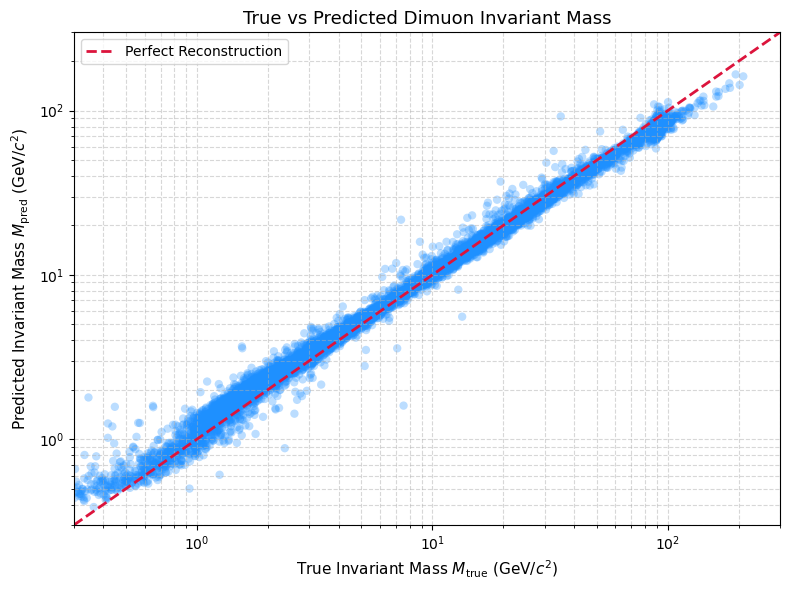

In [50]:
fig1, ax1 = plt.subplots(figsize=(8, 6))
ax1.scatter(y_test_physical, y_pred_physical, alpha=0.3, color='dodgerblue', edgecolor='none')
ax1.plot([0.3, 300], [0.3, 300], color='crimson', linestyle='--', linewidth=2, label='Perfect Reconstruction')
ax1.set_xscale('log')
ax1.set_yscale('log')
ax1.set_xlim(0.3, 300)
ax1.set_ylim(0.3, 300)
ax1.set_xlabel("True Invariant Mass $M_{\\text{true}}$ (GeV/$c^2$)", fontsize=11)
ax1.set_ylabel("Predicted Invariant Mass $M_{\\text{pred}}$ (GeV/$c^2$)", fontsize=11)
ax1.set_title("True vs Predicted Dimuon Invariant Mass", fontsize=13)
ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax1.legend()
plt.tight_layout()
plt.savefig('plot1_invariant_mass.png', dpi=150, bbox_inches='tight')
plt.show()

<h3> Relative Residual Distribution (Mass Resolution)

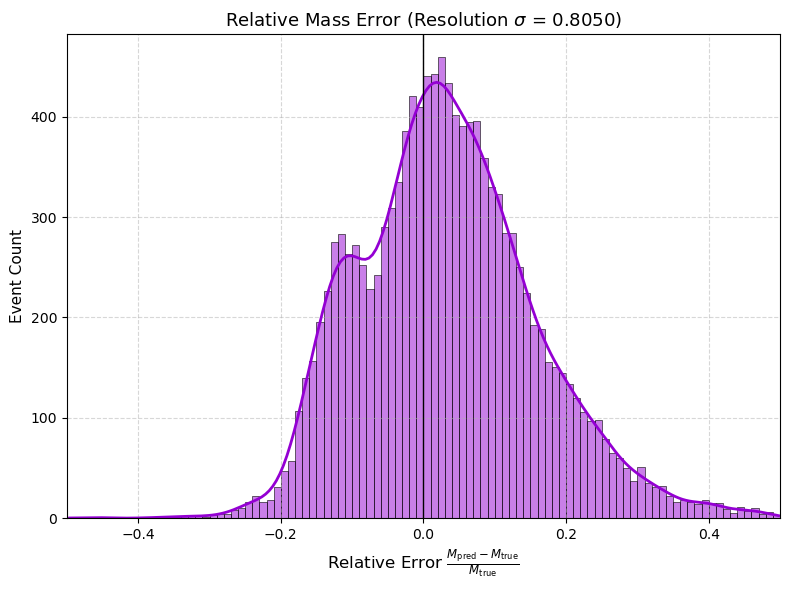

In [62]:
filtered_errors = relative_errors[(relative_errors >= -0.5) & (relative_errors <= 0.5)]
# Filter the data to the visible range so the KDE calculates correctly


fig2, ax2 = plt.subplots(figsize=(8, 6))
sns.histplot(filtered_errors, 
             bins=100, 
             binrange=(-0.5, 0.5), 
             kde=True, 
             ax=ax2, 
             color='darkviolet', 
             edgecolor='black', 
             
ax2.axvline(0, color='black', linestyle='-', linewidth=1)
ax2.set_xlim(-0.5, 0.5)
ax2.set_xlabel(r"Relative Error $\frac{M_{\text{pred}} - M_{\text{true}}}{M_{\text{true}}}$", fontsize=12)
ax2.set_ylabel("Event Count", fontsize=11)
ax2.set_title(f"Relative Mass Error (Resolution $\sigma$ = {resolution_std:.4f})", fontsize=13)
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig('plot2_relative_error.png', dpi=150, bbox_inches='tight')
plt.show()


    # binrange=(-0.5, 0.5)  Forces 100 bins inside the visible window

<h3> Log-Space Residuals vs Invariant Mass Scale

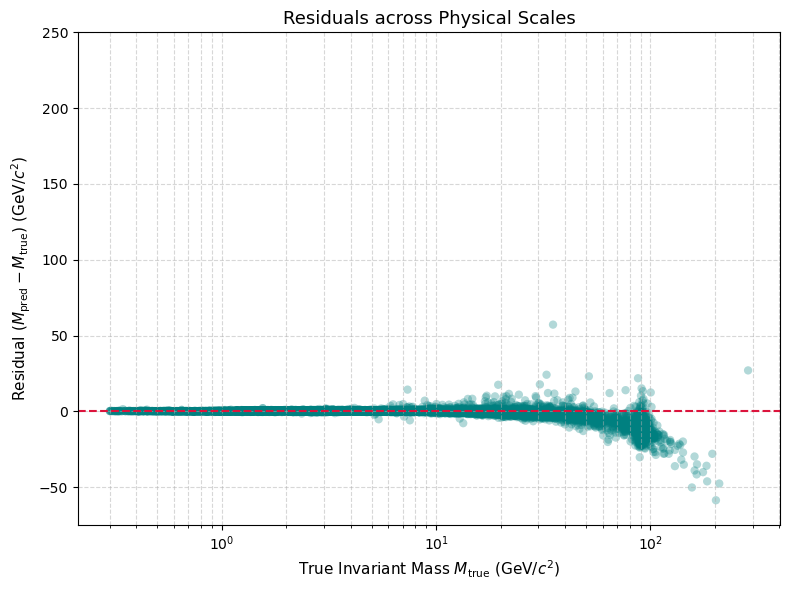

In [65]:
fig3, ax3 = plt.subplots(figsize=(8, 6))
ax3.scatter(y_test_physical, y_pred_physical - y_test_physical, alpha=0.3, color='teal', edgecolor='none')
ax3.axhline(0, color='crimson', linestyle='--', linewidth=1.5)
ax3.set_xscale('log')
ax3.set_ylim(-75, 250)
ax3.set_xlabel("True Invariant Mass $M_{\\text{true}}$ (GeV/$c^2$)", fontsize=11)
ax3.set_ylabel("Residual ($M_{\\text{pred}} - M_{\\text{true}}$) (GeV/$c^2$)", fontsize=11)
ax3.set_title("Residuals across Physical Scales", fontsize=13)
ax3.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig('plot3_residuals.png', dpi=150, bbox_inches='tight')
plt.show()



<h3> Spectrum Reconstruction Comparison

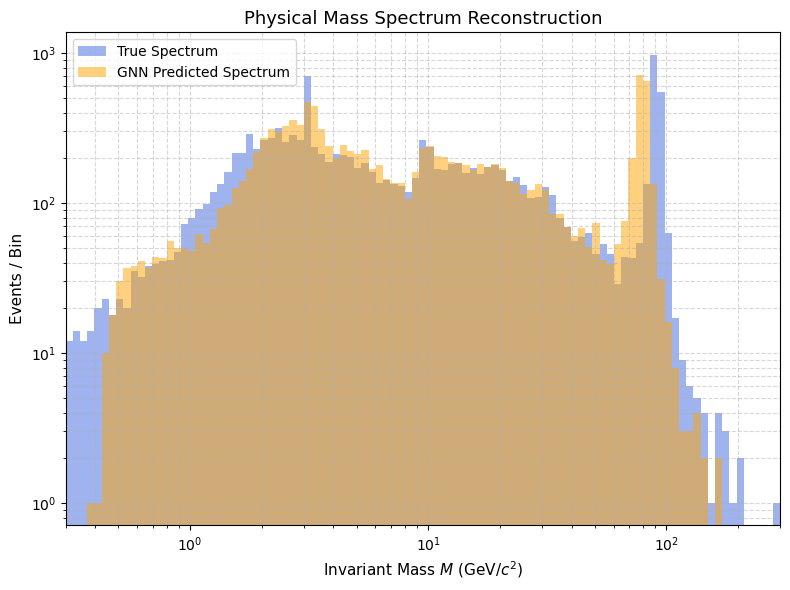

In [66]:
fig4, ax4 = plt.subplots(figsize=(8, 6))
log_bins = np.logspace(np.log10(0.3), np.log10(300), 100)
ax4.hist(y_test_physical, bins=log_bins, alpha=0.5, color='royalblue', label='True Spectrum', histtype='stepfilled')
ax4.hist(y_pred_physical, bins=log_bins, alpha=0.5, color='orange', label='GNN Predicted Spectrum', histtype='stepfilled')
ax4.set_xscale('log')
ax4.set_yscale('log')
ax4.set_xlim(0.3, 300)
ax4.set_xlabel("Invariant Mass $M$ (GeV/$c^2$)", fontsize=11)
ax4.set_ylabel("Events / Bin", fontsize=11)
ax4.set_title("Physical Mass Spectrum Reconstruction", fontsize=13)
ax4.grid(True, which="both", linestyle="--", alpha=0.5)
ax4.legend()
plt.tight_layout()
plt.savefig('plot4_spectrum.png', dpi=150, bbox_inches='tight')
plt.show()